# Evaluación del modelo (Fase 2)

¿El LSTM predice los Mundiales mejor que reglas simples? Este notebook **no entrena ni copia código**: importa las funciones de `web/fases/` y lee lo que dejó `python manage.py evaluar_modelos`.

**Partición temporal (nada del futuro):**
- *Selección de configuración*: entrena con los ciclos hasta 2010 (eliminatorias y Mundiales) y valida con el ciclo 2014 completo.
- *Prueba*: reentrena hasta 2014 y mide **una sola vez** en los 128 partidos de los Mundiales 2018 y 2022.

**Métricas:** MAE de goles, % de resultado acertado (local / empate / visitante), % de marcador exacto y *deviance* de Poisson (menor es mejor).

In [1]:
import json, os, sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "web"))
os.environ.setdefault("DJANGO_SETTINGS_MODULE", "mundial.settings")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
import django
django.setup()

import pandas as pd
import matplotlib.pyplot as plt
from fases.dataset import construir_secuencias
from fases.evaluacion import evaluar, particion
from fases.predictores import cargar_predictor

resultados = json.loads((RAIZ / "experimentos" / "resultados_baseline.json").read_text(encoding="utf-8"))
print(resultados["fecha"], "-", resultados["partidos"], "partidos en", resultados["dataset"])

2026-10-23 - 9833 partidos en partidos_features.csv


## 1. Selección: largo de la secuencia (K), bloques de la entrada y contexto adicional

Media ± desviación de 3 semillas en la validación (ciclo 2014, 868 partidos). La deviance de Poisson es la medida de elección (menor es mejor).

In [2]:
filas = []
for s in resultados["seleccion"]:
    v = s["validacion"]
    filas.append({"K": s["k"], "rival": s["con_rival"], "contexto": s["con_contexto"], "extras": ", ".join(s.get("extras", [])) or "-",
                  "deviance": f'{v["deviance"]["media"]:.4f} ± {v["deviance"]["desv"]:.4f}',
                  "acierto %": f'{v["acierto_resultado"]["media"]:.1f} ± {v["acierto_resultado"]["desv"]:.1f}'})
pd.DataFrame(filas)

,K,rival,contexto,extras,deviance,acierto %
0,1,True,True,-,0.7392 ± 0.0027,59.9 ± 0.2
1,3,True,True,-,0.7438 ± 0.0008,59.6 ± 0.4
2,5,True,True,-,0.7465 ± 0.0011,59.0 ± 0.5
3,8,True,True,-,0.7432 ± 0.0017,59.9 ± 0.2
4,12,True,True,-,0.7390 ± 0.0007,60.4 ± 0.4
5,1,False,True,-,0.7403 ± 0.0007,59.9 ± 0.4
6,1,True,False,-,0.7577 ± 0.0010,58.1 ± 0.2
7,1,False,False,-,0.7576 ± 0.0006,58.1 ± 0.1
8,1,False,True,elo,0.7223 ± 0.0020,61.2 ± 0.2
9,1,False,True,fase,0.7423 ± 0.0003,60.0 ± 0.6


In [3]:
elegida = resultados["elegida"]
print("Configuración elegida:", elegida)
u = resultados["umbral_empate"]
print(f"Acierto en validación sin umbral de empate: {u['acierto_validacion'][0] * 100:.1f}% -> con el umbral elegido: {max(u['acierto_validacion']) * 100:.1f}%")

Configuración elegida: {'k': 1, 'con_rival': False, 'con_contexto': True, 'extras': ['elo'], 'epocas': 5, 'umbral_empate': 0.01}
Acierto en validación sin umbral de empate: 61.2% -> con el umbral elegido: 61.3%


## 2. Pruebas: Mundiales 2018 y 2022 (entrenando hasta 2014) y Mundial 2026 (entrenando hasta 2022)

In [4]:
nombres = {"medias": "(b) Poisson con medias", "mas_puntos": "(a) gana el de más puntos", "empate": "(c) siempre 1-1",
           "lstm": "LSTM", "lstm_sin_umbral": "LSTM sin umbral de empate"}

def tabla_de(prueba):
    filas = []
    for clave, r in prueba.items():
        valor = (lambda m: r[m]["media"]) if clave.startswith("lstm") else (lambda m: r[m])
        filas.append({"modelo": nombres[clave], "acierto resultado %": round(valor("acierto_resultado"), 1),
                      "marcador exacto %": round(valor("marcador_exacto"), 1), "MAE goles": round(valor("mae_goles"), 3),
                      "deviance": round(valor("deviance"), 3)})
    return pd.DataFrame(filas).set_index("modelo")

tabla_18_22, tabla_26 = tabla_de(resultados["prueba"]), tabla_de(resultados["prueba_2026"])
display(tabla_18_22)
tabla_26

,acierto resultado %,marcador exacto %,MAE goles,deviance
modelo,,,,
(b) Poisson con medias,43.0,10.2,0.984,0.957
(a) gana el de más puntos,46.1,8.6,1.094,11.683
(c) siempre 1-1,21.9,9.4,0.902,1.000
LSTM,53.9,10.7,0.920,0.917
LSTM sin umbral de empate,53.9,10.4,0.920,0.917


,acierto resultado %,marcador exacto %,MAE goles,deviance
modelo,,,,
(b) Poisson con medias,47.1,6.7,1.050,0.883
(a) gana el de más puntos,51.0,10.6,1.188,13.258
(c) siempre 1-1,23.1,11.5,1.010,1.000
LSTM,63.8,9.0,0.945,0.773


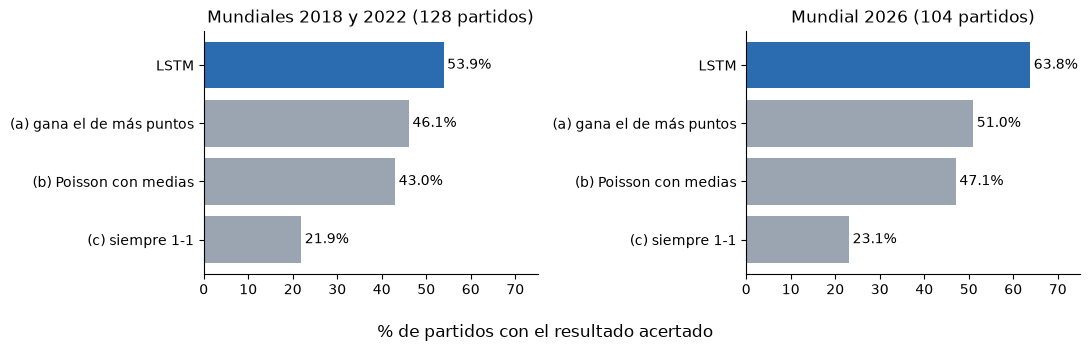

In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5), sharex=True)
for ax, tabla, titulo in ((ejes[0], tabla_18_22, "Mundiales 2018 y 2022 (128 partidos)"), (ejes[1], tabla_26, "Mundial 2026 (104 partidos)")):
    datos = tabla.drop(index="LSTM sin umbral de empate", errors="ignore")["acierto resultado %"].sort_values()
    ax.barh(datos.index, datos.values, color=["#9aa5b1" if m != "LSTM" else "#2b6cb0" for m in datos.index])
    for y, x in enumerate(datos.values):
        ax.text(x + 0.8, y, f"{x:.1f}%", va="center")
    ax.set_title(titulo)
    ax.set_xlim(0, 75)
    ax.spines[["top", "right"]].set_visible(False)
fig.supxlabel("% de partidos con el resultado acertado")
plt.tight_layout()
plt.show()

## 3. Comprobación: el modelo guardado da lo mismo

El modelo de `data/modelos/lstm-<fecha>/` (el que usa la app) se entrenó hasta 2022. Se carga con `cargar_predictor` y se evalúa de nuevo en 2026 con `evaluar`, las mismas funciones que usa el comando.

In [6]:
ds = pd.read_csv(RAIZ / "data" / "datasets" / "partidos_features.csv")
predictor, esquema = cargar_predictor(RAIZ / "data" / "modelos" / resultados["modelo"])
c = esquema["config"]
sec = construir_secuencias(ds, k=c["k"], con_rival=c["con_rival"], con_contexto=c["con_contexto"], extras=c.get("extras", []))
_, _, prueba_2026 = particion(ds, hasta=2022, prueba=[2026])
evaluar(predictor, ds, sec, prueba_2026)

{'partidos': 104,
 'mae_goles': 0.9463433998708541,
 'acierto_resultado': 66.34615384615384,
 'marcador_exacto': 8.653846153846153,
 'deviance': 0.7742606668969061}

## 4. Lectura

- **Frase para el README:** el LSTM acierta el resultado en ~54 % de los partidos de 2018–2022 (mejor línea base: 46 %) y en ~64 % de los de 2026, que nunca vio (mejor línea base: 51 %).
- **El Elo es el contexto que más aporta:** baja la deviance de validación de ~0,740 a ~0,722. Fase del torneo, local continental, descanso y situación en el grupo no mejoran más que el ruido entre semillas.
- **Cuidado con el tamaño de cada prueba:** 128 o 104 partidos dan un margen de unos ±9 puntos (intervalo del 95 %). Cada prueba sola se lee como "probablemente mejor"; lo que da confianza es que la ventaja se repite en validación (868 partidos) y en las dos pruebas.
- **Umbral de empate:** con dos Poisson el empate casi nunca es el resultado más probable; el umbral elegido en validación apenas cambia los números.
- **K = 1:** ver más partidos pasados no mejora; cada paso ya trae las métricas *acumuladas* del ciclo y el Elo.
- **MAE:** "siempre 1-1" tiene MAE bajo porque 1 gol es casi la mediana; por eso no se usa para elegir modelo.
- **Marcador exacto (~9-11 %)**: parecido para todos; predecir el marcador exacto en fútbol es casi azar.